# Skull stripping and the volume

`process.py` turns each IXI T1 into a brain volume in millilitres. It does that in two steps. FreeSurfer `mri_synthstrip` clears the tissue outside the brain. `nibabel_volume.measure` then counts the remaining voxels and multiplies by the voxel size stored in the NIfTI header.

This notebook follows one scan, `IXI002-Guys-0828-T1`, through both steps. The same steps run on all 581 scans. Charts for the whole set are in `results.ipynb`.

Opening this notebook only reads images that are already on disk. It does not run SynthStrip again.

In [9]:
%matplotlib inline

import csv
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import nibabel as nib
import numpy as np
from matplotlib.patches import Patch, Rectangle

ROOT = Path.cwd()
if not (ROOT / "nibabel_volume.py").exists():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from nibabel_volume import measure

SUBJECT = "IXI002-Guys-0828-T1"
raw_path = ROOT / "data" / "IXI-T1" / f"{SUBJECT}.nii"
brain_path = ROOT / "data" / "brains" / f"{SUBJECT}_brain.nii.gz"
if not brain_path.exists():
    raise FileNotFoundError(f"missing {brain_path}. Run python process.py first.")

# Brighter than this, a cleared voxel is tinted in the overlay.
# Dimmer background speckle is cleared too, and left untinted so the head stays readable.
BRIGHT = 40

raw_img = nib.load(raw_path)
brain_img = nib.load(brain_path)
raw = np.asanyarray(raw_img.dataobj)
brain = np.asanyarray(brain_img.dataobj)
zooms = np.array(raw_img.header.get_zooms()[:3], dtype=np.float64)
mask = brain != 0
centroid = np.argwhere(mask).mean(axis=0)
index = tuple(int(round(float(v))) for v in centroid)
vmax = float(np.percentile(raw[raw > 0], 99))


def display_planes(volume, index, zooms):
    # Axes are posterior, superior, right.
    # Sagittal faces left. Coronal and axial put the patient's right on the left.
    # Superior is up. On the axial slice, anterior is up.
    i_p, i_s, i_r = (int(i) for i in index)
    zp, zs, zr = (float(z) for z in zooms)
    slices = (
        volume[:, ::-1, i_r].T,
        volume[i_p, ::-1, ::-1],
        volume[:, i_s, ::-1],
    )
    aspects = (zs / zp, zs / zr, zp / zr)
    names = ("Sagittal", "Coronal", "Axial")
    return list(zip(names, slices, aspects))


def draw_slice(ax, image, aspect, vmax):
    ax.imshow(
        image,
        cmap="gray",
        vmin=0,
        vmax=vmax,
        origin="upper",
        interpolation="nearest",
        aspect=aspect,
    )
    ax.set_xticks([])
    ax.set_yticks([])


planes_raw = display_planes(raw, index, zooms)
planes_brain = display_planes(brain, index, zooms)

## How the strip is made

`process.py` calls FreeSurfer through WSL, from the install named in `freesurfer.sh`. For a scan that is not already marked `ok` in `results/volumes.csv`, the command is:

```sh
mri_synthstrip -i data/IXI-T1/IXI002-Guys-0828-T1.nii -o data/brains/IXI002-Guys-0828-T1_brain.nii.gz
```

SynthStrip is a 3D U-Net trained to find the brain boundary on a T1 weighted scan (Hoopes et al., NeuroImage 260 (2022) 119474). It writes a new image on the same grid and the same affine. Intensities inside the brain are copied. Scalp, skull, eyes, face, and neck are written as 0. Cerebrospinal fluid inside the brain is kept, including the ventricles, so the volume below is the whole stripped brain.

The next cell checks those claims on this file.

In [10]:
codes = nib.aff2axcodes(raw_img.affine)
print(f"shape {raw.shape}")
print(f"axes {' '.join(codes)}")
print(f"voxel mm {zooms[0]:.4f} x {zooms[1]:.4f} x {zooms[2]:.4f}")
print(f"same shape {raw.shape == brain.shape}")
print(f"same affine {bool(np.allclose(raw_img.affine, brain_img.affine))}")

changed = raw != brain
print(f"voxels changed {int(changed.sum())}")
print(f"changed voxels inside the brain {int(np.count_nonzero(changed & mask))}")
print(f"values written outside {np.unique(brain[changed & ~mask]).tolist()}")
print(f"nonzero voxels before {int(np.count_nonzero(raw))}")
print(f"nonzero voxels after {int(mask.sum())}")

shape (256, 256, 150)
axes P S R
voxel mm 0.9375 x 0.9375 x 1.2000
same shape True
same affine True
voxels changed 4186507
changed voxels inside the brain 0
values written outside [0]
nonzero voxels before 5589073
nonzero voxels after 1402566


## Before and after

The slices pass through the centre of the stripped brain. Both rows share one intensity window, so tissue that remains has the same brightness it had in the T1. Black on the lower row is the region SynthStrip set to 0.

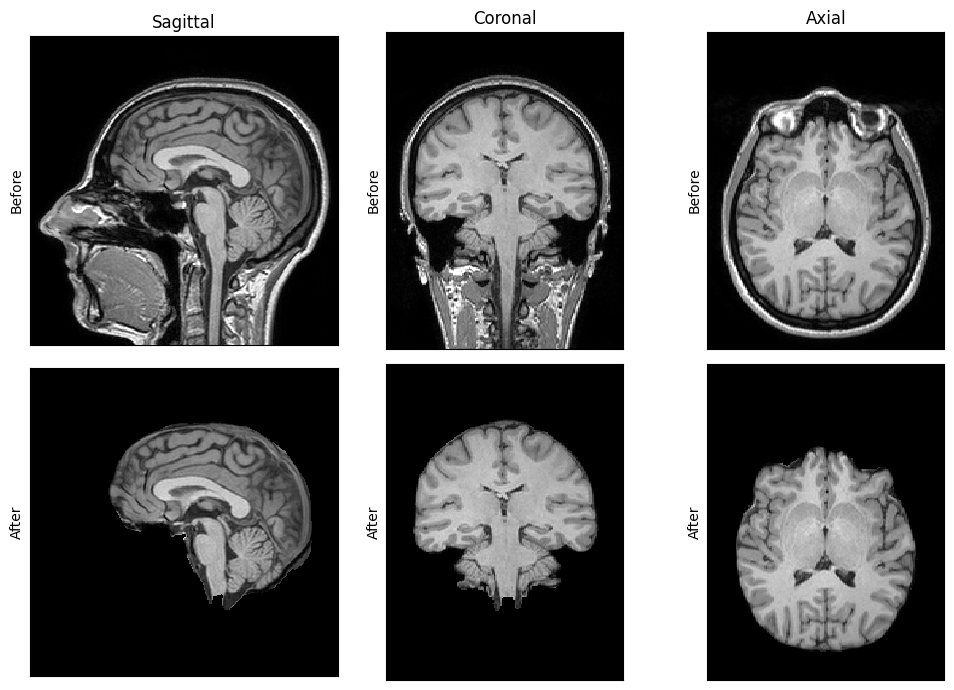

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(10, 7))
for col, ((name, sl_raw, aspect), (_, sl_brain, _)) in enumerate(zip(planes_raw, planes_brain)):
    draw_slice(axes[0, col], sl_raw, aspect, vmax)
    draw_slice(axes[1, col], sl_brain, aspect, vmax)
    axes[0, col].set_title(name)
    axes[0, col].set_ylabel("Before")
    axes[1, col].set_ylabel("After")
fig.tight_layout()
plt.show()

## Tissue the strip clears

Red marks brighter voxels that are present in the T1 and stored as 0 after the strip: scalp, skull, eyes, face, and neck. Fainter background voxels are cleared as well. They stay untinted here so the head remains easy to read.

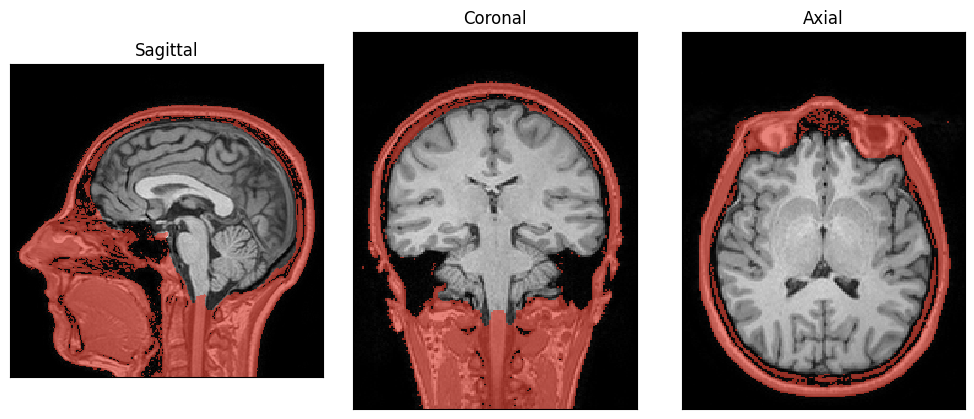

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(10, 4.2))
for ax, (name, sl_raw, aspect), (_, sl_brain, _) in zip(axes, planes_raw, planes_brain):
    draw_slice(ax, sl_raw, aspect, vmax)
    removed = (sl_raw > BRIGHT) & (sl_brain == 0)
    tint = np.zeros((*sl_raw.shape, 4))
    tint[removed] = (0.86, 0.22, 0.16, 0.62)
    ax.imshow(tint, origin="upper", interpolation="nearest", aspect=aspect)
    ax.set_title(name)
fig.tight_layout()
plt.show()

## Voxels that enter the volume

`measure` loads the stripped image and counts voxels whose stored value is not 0. The outside of a SynthStrip image is exactly 0, so the count is the brain, ventricles included. White below is a voxel that counts. Black is a voxel left out.

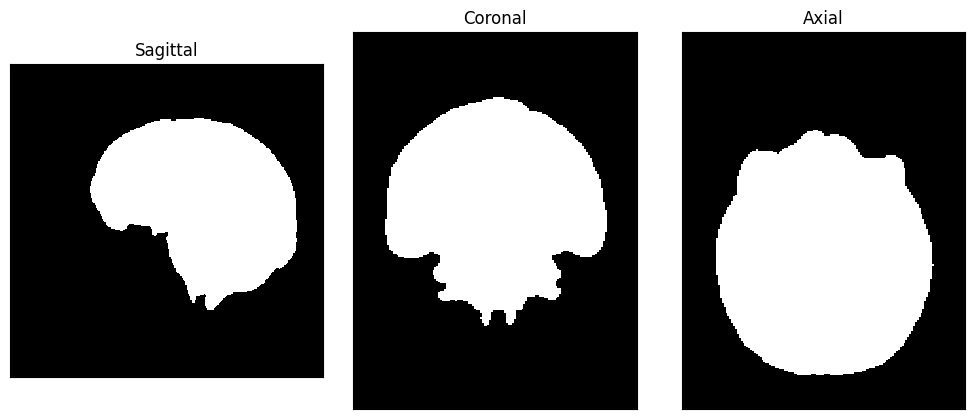

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(10, 4.2))
for ax, (name, sl_brain, aspect) in zip(axes, planes_brain):
    ax.imshow(
        sl_brain != 0,
        cmap="gray",
        vmin=0,
        vmax=1,
        origin="upper",
        interpolation="nearest",
        aspect=aspect,
    )
    ax.set_title(name)
    ax.set_xticks([])
    ax.set_yticks([])
fig.tight_layout()
plt.show()

## One voxel at the boundary

This is the mid sagittal slice where the skull meets the cortex, drawn so each square is one voxel. The two outlines mark the same places in both images. The upper outline is skull in the T1 and 0 after the strip, so that voxel drops out of the count. The lower outline keeps its intensity and counts as one voxel.

The two sides in this plane come from the posterior and superior header zooms. The third side is the left to right thickness, which this slice does not show.

outlined skull voxel  raw 379  stripped 0
outlined brain voxel  raw 284  stripped 284
in plane voxel 0.9375 mm x 0.9375 mm, thickness 1.2000 mm


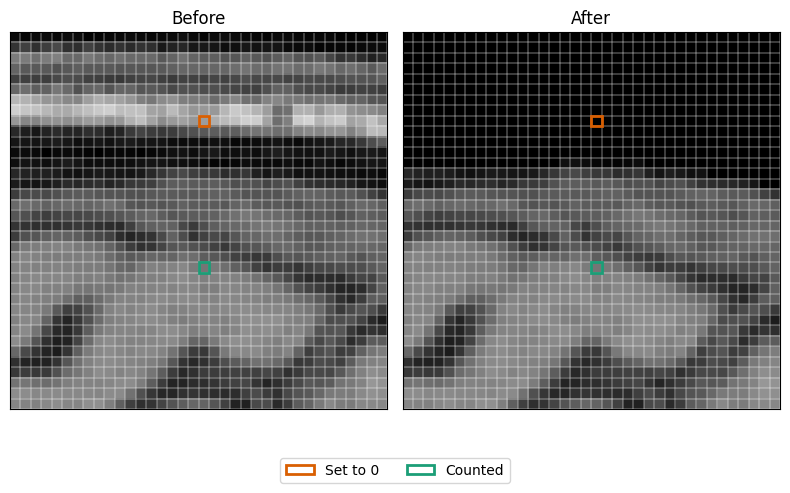

In [14]:
name, sag_raw, aspect = planes_raw[0]
_, sag_brain, _ = planes_brain[0]
kept_rows, kept_cols = np.where(sag_brain != 0)
top = int(kept_rows.min())
edge_cols = kept_cols[kept_rows == top]
col = int(np.median(edge_cols))
kept_at_col = np.where(sag_brain[:, col] != 0)[0]
brain_row = int(kept_at_col[0])
above = slice(max(brain_row - 8, 0), brain_row)
skull_row = int(above.start + np.argmax(sag_raw[above, col]))
# Step past the dark rim so the counted outline sits in bright tissue.
deeper = kept_at_col[sag_brain[kept_at_col, col] >= 280]
if len(deeper):
    brain_row = int(deeper[0])

r0 = max(min(skull_row, brain_row) - 8, 0)
c0 = col - 18
size = 36
r1, c1 = r0 + size, c0 + size
crop_raw = sag_raw[r0:r1, c0:c1]
crop_brain = sag_brain[r0:r1, c0:c1]
marks = {
    (skull_row - r0, col - c0): "#d95f02",
    (brain_row - r0, col - c0): "#1b9e77",
}

fig, axes = plt.subplots(1, 2, figsize=(8, 4.8))
for ax, crop, title in zip(axes, (crop_raw, crop_brain), ("Before", "After")):
    ax.imshow(crop, cmap="gray", vmin=0, vmax=vmax, origin="upper", interpolation="nearest")
    ax.set_xticks(np.arange(-0.5, crop.shape[1], 1), minor=True)
    ax.set_yticks(np.arange(-0.5, crop.shape[0], 1), minor=True)
    ax.grid(which="minor", color="white", linewidth=0.35, zorder=2)
    ax.tick_params(which="both", bottom=False, left=False, labelbottom=False, labelleft=False)
    for (row, column), color in marks.items():
        ax.add_patch(
            Rectangle(
                (column - 0.5, row - 0.5),
                1,
                1,
                fill=False,
                edgecolor=color,
                linewidth=2,
                zorder=3,
            )
        )
    ax.set_title(title)

skull_value = int(sag_raw[skull_row, col])
kept_value = int(sag_brain[brain_row, col])
print(f"outlined skull voxel  raw {skull_value}  stripped {int(sag_brain[skull_row, col])}")
print(f"outlined brain voxel  raw {int(sag_raw[brain_row, col])}  stripped {kept_value}")
print(f"in plane voxel {zooms[0]:.4f} mm x {zooms[1]:.4f} mm, thickness {zooms[2]:.4f} mm")

fig.legend(
    handles=[
        Patch(facecolor="none", edgecolor="#d95f02", linewidth=2, label="Set to 0"),
        Patch(facecolor="none", edgecolor="#1b9e77", linewidth=2, label="Counted"),
    ],
    loc="upper center",
    bbox_to_anchor=(0.5, 0.06),
    ncol=2,
    frameon=True,
)
fig.tight_layout(rect=(0, 0.08, 1, 1))
plt.show()

## The arithmetic

The header zooms are the voxel sides in millimetres, in the order posterior, superior, right. Their product is the volume of one voxel in cubic millimetres. One millilitre is 1000 cubic millimetres.

```text
volume_ml = nonzero_voxels * zoom_p * zoom_s * zoom_r / 1000
```

That is `measure` in `nibabel_volume.py`. `process.py` calls it on each stripped image and writes the result to `results/volumes.csv`.

In [15]:
voxels, voxel_mm3, ml = measure(brain_path)
print(f"{zooms[0]:.6f} x {zooms[1]:.6f} x {zooms[2]:.6f} = {voxel_mm3:.6f} mm3")
print(f"{voxels} voxels x {voxel_mm3:.6f} mm3 / 1000 = {ml:.3f} ml")

with (ROOT / "results" / "volumes.csv").open(newline="", encoding="utf-8") as handle:
    saved = next(row for row in csv.DictReader(handle) if row["subject"] == SUBJECT)
print(f"csv voxels {saved['voxels']}  voxel_mm3 {saved['voxel_mm3']}  volume_ml {saved['volume_ml']}")
if saved["voxels"] != str(voxels) or saved["volume_ml"] != f"{ml:.3f}":
    raise AssertionError("measure does not match results/volumes.csv")

0.937500 x 0.937500 x 1.199997 = 1.054685 mm3
1402566 voxels x 1.054685 mm3 / 1000 = 1479.265 ml
csv voxels 1402566  voxel_mm3 1.054685  volume_ml 1479.265


## Why the strip comes first

The same multiplication on the raw T1 counts every nonzero voxel in the head. That includes scalp, skull, face, neck, and faint background. The bar puts that figure beside the stripped volume stored in the CSV. The stripped bar is the brain volume for this scan.

raw nonzero volume 5894.7 ml
stripped volume 1479.3 ml


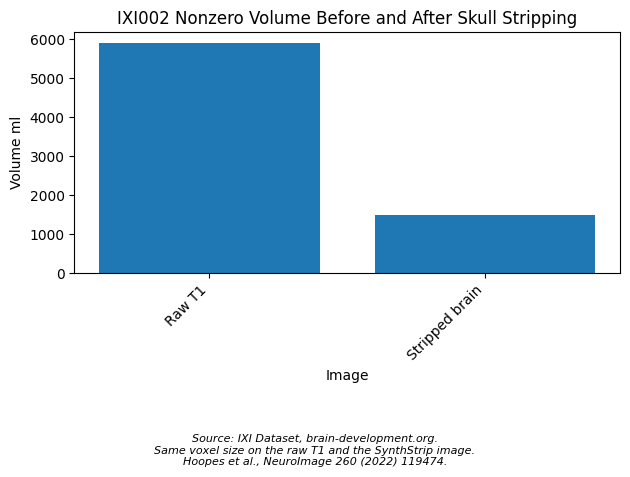

In [16]:
raw_voxels = int(np.count_nonzero(raw))
raw_ml = raw_voxels * voxel_mm3 / 1000.0
print(f"raw nonzero volume {raw_ml:.1f} ml")
print(f"stripped volume {ml:.1f} ml")

source = (
    "Source: IXI Dataset, brain-development.org.\n"
    "Same voxel size on the raw T1 and the SynthStrip image.\n"
    "Hoopes et al., NeuroImage 260 (2022) 119474."
)

fig, ax = plt.subplots()
labels = ["Raw T1", "Stripped brain"]
values = [raw_ml, ml]
ax.bar(labels, values)
ax.set_title("IXI002 Nonzero Volume Before and After Skull Stripping")
ax.set_xlabel("Image")
ax.set_ylabel("Volume ml")
plt.xticks(rotation=45, ha="right")
fig.tight_layout()
# Three source lines need more room than the axis label, or they sit on it.
fig.subplots_adjust(bottom=0.42)
plt.figtext(0.5, 0.02, source, ha="center", fontsize=8, style="italic")
plt.show()